**Arquivo ZIP do Projeto Final — Google Drive:**

[Baixar o projeto completo](https://drive.google.com/file/d/1DsFdFuRPFovoJ1bqfozshrQaC0W4WU3V/view?usp=drive_link)

# Projeto Final — Análise de Eficiência dos Operadores da CallMeMaybe

## Introdução

A CallMeMaybe oferece serviços de telefonia virtual para organizações. A empresa deseja identificar operadores de atendimento que apresentam possíveis problemas de eficiência, a fim de melhorar a qualidade do serviço prestado aos clientes.

Nesta análise, investigaremos três indicadores principais:

- Proporção de chamadas recebidas perdidas.
- Tempo médio de espera nas chamadas recebidas.
- Quantidade de chamadas de saída realizadas pelos operadores responsáveis por esse tipo de atendimento.

## Objetivo

Analisar os dados de chamadas e operadores da CallMeMaybe, identificar possíveis operadores menos eficientes e apresentar recomendações fundamentadas nos resultados, considerando as limitações dos dados disponíveis.

## 1. Preparação e exploração inicial dos dados

Nesta etapa, serão importadas as bibliotecas necessárias, carregados os conjuntos de dados e examinadas suas estruturas, incluindo os tipos das colunas e a presença de valores ausentes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
chamadas = pd.read_csv('/datasets/telecom_dataset_us.csv')
clientes = pd.read_csv('/datasets/telecom_clients_us.csv')

print('Chamadas:', chamadas.shape)
print('Clientes:', clientes.shape)

Chamadas: (53902, 9)
Clientes: (732, 3)


In [3]:
chamadas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53902 entries, 0 to 53901
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              53902 non-null  int64  
 1   date                 53902 non-null  object 
 2   direction            53902 non-null  object 
 3   internal             53785 non-null  object 
 4   operator_id          45730 non-null  float64
 5   is_missed_call       53902 non-null  bool   
 6   calls_count          53902 non-null  int64  
 7   call_duration        53902 non-null  int64  
 8   total_call_duration  53902 non-null  int64  
dtypes: bool(1), float64(1), int64(4), object(3)
memory usage: 3.3+ MB


In [4]:
clientes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      732 non-null    int64 
 1   tariff_plan  732 non-null    object
 2   date_start   732 non-null    object
dtypes: int64(1), object(2)
memory usage: 17.3+ KB


In [5]:
print('Duplicatas em chamadas:', chamadas.duplicated().sum())
print('Duplicatas em clientes:', clientes.duplicated().sum())

Duplicatas em chamadas: 4900
Duplicatas em clientes: 0


### 1.1 Investigação de registros duplicados

Foram identificados 4.900 registros duplicados no conjunto de chamadas e nenhum no conjunto de clientes.

Antes de realizar qualquer exclusão, será investigada a natureza dessas duplicatas, considerando que cada registro pode representar múltiplas chamadas por meio da coluna `calls_count`.

In [6]:
duplicatas = chamadas[chamadas.duplicated(keep=False)]

duplicatas.head(10)

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
6,166377,2019-08-05 00:00:00+03:00,out,False,880020.0,True,8,0,50
8,166377,2019-08-05 00:00:00+03:00,out,False,880020.0,True,8,0,50
27,166377,2019-08-12 00:00:00+03:00,in,False,NaN,True,2,0,34
28,166377,2019-08-12 00:00:00+03:00,in,False,NaN,True,2,0,34
38,166377,2019-08-14 00:00:00+03:00,in,False,NaN,True,1,0,3
43,166377,2019-08-14 00:00:00+03:00,out,False,880026.0,False,10,1567,1654
44,166377,2019-08-14 00:00:00+03:00,out,False,880026.0,False,10,1567,1654
45,166377,2019-08-14 00:00:00+03:00,in,False,NaN,True,1,0,3
46,166377,2019-08-15 00:00:00+03:00,out,False,880026.0,False,11,1413,1473
51,166377,2019-08-15 00:00:00+03:00,out,False,880026.0,False,11,1413,1473


In [7]:
print('Chamadas nos registros duplicados:',
      chamadas.loc[chamadas.duplicated(), 'calls_count'].sum())

print('Total de chamadas no arquivo:',
      chamadas['calls_count'].sum())

Chamadas nos registros duplicados: 80046
Total de chamadas no arquivo: 886755


In [8]:
chamadas_limpas = chamadas.drop_duplicates().copy()

print('Registros originais:', len(chamadas))
print('Registros após remover duplicatas:', len(chamadas_limpas))
print('Duplicatas restantes:', chamadas_limpas.duplicated().sum())

Registros originais: 53902
Registros após remover duplicatas: 49002
Duplicatas restantes: 0


**Tratamento dos registros duplicados**

Foram identificados 4.900 registros totalmente duplicados, associados a 80.046 chamadas contabilizadas em `calls_count`, aproximadamente 9,03% do volume original.

Como esses registros apresentavam valores idênticos em todas as colunas, optou-se por remover as repetições para evitar possíveis contagens duplicadas.

Após a limpeza, o conjunto passou de 53.902 para 49.002 registros, sem duplicatas restantes. Os dados originais foram preservados para consulta.

### 1.2 Investigação de valores ausentes

Nesta etapa, serão analisados os valores ausentes no conjunto de chamadas, especialmente nas colunas `operator_id` e `internal`, para decidir como tratá-los sem comprometer a análise de eficiência dos operadores.

In [9]:
chamadas_limpas.isna().sum()

user_id                   0
date                      0
direction                 0
internal                110
operator_id            7456
is_missed_call            0
calls_count               0
call_duration             0
total_call_duration       0
dtype: int64

In [10]:
pd.crosstab(
    chamadas_limpas['direction'],
    chamadas_limpas['operator_id'].isna()
)

operator_id,False,True
direction,,
in,12733,7270
out,28813,186


In [11]:
pd.crosstab(
    chamadas_limpas['operator_id'].isna(),
    chamadas_limpas['is_missed_call']
)

is_missed_call,False,True
operator_id,,
False,27436,14110
True,113,7343


In [12]:
pd.crosstab(
    chamadas_limpas['direction'],
    [
        chamadas_limpas['operator_id'].isna(),
        chamadas_limpas['is_missed_call']
    ]
)

operator_id     False        True       
is_missed_call  False  True  False True 
direction                               
in              12048    685    68  7202
out             15388  13425    45   141

In [13]:
pd.crosstab(
    chamadas_limpas['direction'],
    chamadas_limpas['internal'].isna()
)

internal,False,True
direction,,
in,19895,108
out,28997,2


In [14]:
pd.crosstab(
    chamadas_limpas['internal'].isna(),
    chamadas_limpas['operator_id'].isna()
)

operator_id,False,True
internal,,
False,41491,7401
True,55,55


**Conclusão da investigação de valores ausentes**

Após a remoção das duplicatas, foram identificados 7.456 registros sem `operator_id` e 110 registros sem `internal`.

Entre os registros sem identificação do operador, 7.343 estão marcados como chamadas perdidas, sendo 7.202 de chamadas recebidas. Isso sugere que parte dessas chamadas pode ter sido perdida antes da atribuição a um operador, embora os dados não permitam confirmar essa causa.

Dos 110 registros sem `internal`, 55 possuem operador identificado e 55 também apresentam ausência de `operator_id`.

**Decisões de tratamento:**

- Preservar os registros sem `operator_id` para análises gerais, mas excluí-los dos cálculos de eficiência por operador.
- Manter os valores ausentes de `internal` como desconhecidos, sem preenchimento artificial.
- Considerar `calls_count` nos cálculos dos indicadores, pois cada registro pode representar múltiplas chamadas.

Essas decisões buscam preservar informações relevantes e evitar atribuições incorretas aos operadores.

### 1.3 Conversão dos tipos de dados

Nesta etapa, serão convertidas as colunas de datas para o formato adequado, permitindo realizar análises temporais das chamadas e dos clientes.

In [15]:
chamadas_limpas['date'] = pd.to_datetime(
    chamadas_limpas['date'],
    utc=True
)

print(chamadas_limpas['date'].dtype)

datetime64[ns, UTC]


In [16]:
clientes['date_start'] = pd.to_datetime(
    clientes['date_start']
)

print(clientes['date_start'].dtype)

datetime64[ns]


In [17]:
print('Primeira chamada:', chamadas_limpas['date'].min())
print('Última chamada:', chamadas_limpas['date'].max())

Primeira chamada: 2019-08-01 21:00:00+00:00
Última chamada: 2019-11-27 21:00:00+00:00


In [18]:
print('Primeiro cliente:', clientes['date_start'].min())
print('Último cliente:', clientes['date_start'].max())

Primeiro cliente: 2019-08-01 00:00:00
Último cliente: 2019-10-31 00:00:00


**Conclusão da conversão de datas**

As colunas `date` e `date_start` foram convertidas para o formato de data, permitindo análises temporais.

O conjunto de chamadas abrange o período de 01/08/2019 a 27/11/2019, enquanto os cadastros de clientes ocorreram entre 01/08/2019 e 31/10/2019.

Essas informações serão consideradas nas próximas etapas, especialmente na comparação entre operadores, pois diferenças no período de atividade podem influenciar o volume de chamadas registrado.

### 1.4 Verificação da consistência dos dados

Nesta etapa, serão investigados possíveis valores inconsistentes nas quantidades e durações das chamadas, antes do cálculo dos indicadores de eficiência.

In [19]:
print('Quantidades negativas:', (chamadas_limpas['calls_count'] < 0).sum())
print('Durações negativas:', (chamadas_limpas['call_duration'] < 0).sum())
print('Durações totais negativas:', (chamadas_limpas['total_call_duration'] < 0).sum())

print(
    'Tempo total menor que o tempo de chamada:',
    (chamadas_limpas['total_call_duration'] < chamadas_limpas['call_duration']).sum()
)

Quantidades negativas: 0
Durações negativas: 0
Durações totais negativas: 0
Tempo total menor que o tempo de chamada: 0


In [20]:
print('Registros com zero chamadas:',
      (chamadas_limpas['calls_count'] == 0).sum())

print('Registros com duração total zero:',
      (chamadas_limpas['total_call_duration'] == 0).sum())

Registros com zero chamadas: 0
Registros com duração total zero: 1195


In [21]:
pd.crosstab(
    chamadas_limpas['total_call_duration'] == 0,
    chamadas_limpas['is_missed_call']
)

is_missed_call,False,True
total_call_duration,,
False,27547,20260
True,2,1193


In [22]:
chamadas_limpas[
    (chamadas_limpas['total_call_duration'] == 0) &
    (chamadas_limpas['is_missed_call'] == False)
]

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
9520,166658,2019-11-05 21:00:00+00:00,out,True,890410.0,False,1,0,0
23096,167078,2019-10-22 21:00:00+00:00,out,True,935348.0,False,1,0,0


**Conclusão da verificação de consistência**

Não foram identificadas quantidades ou durações negativas, nem registros em que a duração total fosse inferior à duração da chamada.

Todos os registros apresentam `calls_count` maior que zero.

Foram identificados 1.195 registros com duração total igual a zero. Desses, 1.193 estão marcados como chamadas perdidas e apenas 2 como chamadas não perdidas.

Os dois registros não perdidos correspondem a chamadas internas de saída, com operador identificado e duração zero. Como não é possível confirmar que representam erros, optou-se por preservá-los.

Portanto, não serão realizadas exclusões adicionais nesta etapa. Essas particularidades serão consideradas na interpretação dos indicadores.

### 1.5 Verificação da relação entre as tabelas

Nesta etapa, será verificada a correspondência entre os identificadores dos clientes nos dois conjuntos de dados, utilizando a coluna `user_id`. Essa verificação permitirá avaliar a possibilidade de integrar as informações de chamadas e clientes.

In [23]:
clientes_sem_cadastro = ~chamadas_limpas['user_id'].isin(clientes['user_id'])

print('Registros de chamadas sem cliente correspondente:',
      clientes_sem_cadastro.sum())

Registros de chamadas sem cliente correspondente: 0


In [24]:
dados = chamadas_limpas.merge(
    clientes,
    on='user_id',
    how='left',
    validate='many_to_one'
)

print('Registros após a união:', len(dados))
print('Colunas após a união:', dados.shape[1])

Registros após a união: 49002
Colunas após a união: 11


In [25]:
dados.head()

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration,tariff_plan,date_start
0,166377,2019-08-03 21:00:00+00:00,in,False,NaN,True,2,0,4,B,2019-08-01
1,166377,2019-08-04 21:00:00+00:00,out,True,880022.0,True,3,0,5,B,2019-08-01
2,166377,2019-08-04 21:00:00+00:00,out,True,880020.0,True,1,0,1,B,2019-08-01
3,166377,2019-08-04 21:00:00+00:00,out,True,880020.0,False,1,10,18,B,2019-08-01
4,166377,2019-08-04 21:00:00+00:00,out,False,880022.0,True,3,0,25,B,2019-08-01


**Conclusão da integração dos dados**

A verificação confirmou que todos os registros de chamadas possuem um cliente correspondente na tabela de clientes.

As tabelas foram integradas pela coluna `user_id`, utilizando uma junção à esquerda (`left join`).

O conjunto resultante contém 49.002 registros e 11 colunas, preservando a quantidade original de registros após a remoção das duplicatas.

As informações `tariff_plan` e `date_start` foram incorporadas corretamente, permitindo análises que relacionem o comportamento das chamadas às características dos clientes.

## 2. Análise exploratória dos dados

Nesta etapa, será analisado o comportamento geral das chamadas da CallMeMaybe, considerando o período dos registros, a direção das chamadas, a quantidade de chamadas perdidas e a distribuição da atividade entre os operadores.

O objetivo é compreender os padrões presentes nos dados antes de calcular os indicadores de eficiência.

### 2.1 Período e evolução das chamadas

Nesta seção, será analisada a distribuição das chamadas ao longo do período disponível, buscando identificar variações no volume de chamadas e possíveis padrões temporais.

Para representar o volume de chamadas, será utilizada a soma da coluna `calls_count`, pois cada registro pode representar mais de uma chamada.

In [26]:
chamadas_por_dia = (
    dados.groupby(dados['date'].dt.date)['calls_count']
    .sum()
    .sort_index()
)

print('Total de dias com registros:', len(chamadas_por_dia))
print('Total de chamadas:', chamadas_por_dia.sum())

chamadas_por_dia.head()

Total de dias com registros: 119
Total de chamadas: 806709


date
2019-08-01     21
2019-08-02     29
2019-08-03      6
2019-08-04    192
2019-08-05    229
Name: calls_count, dtype: int64

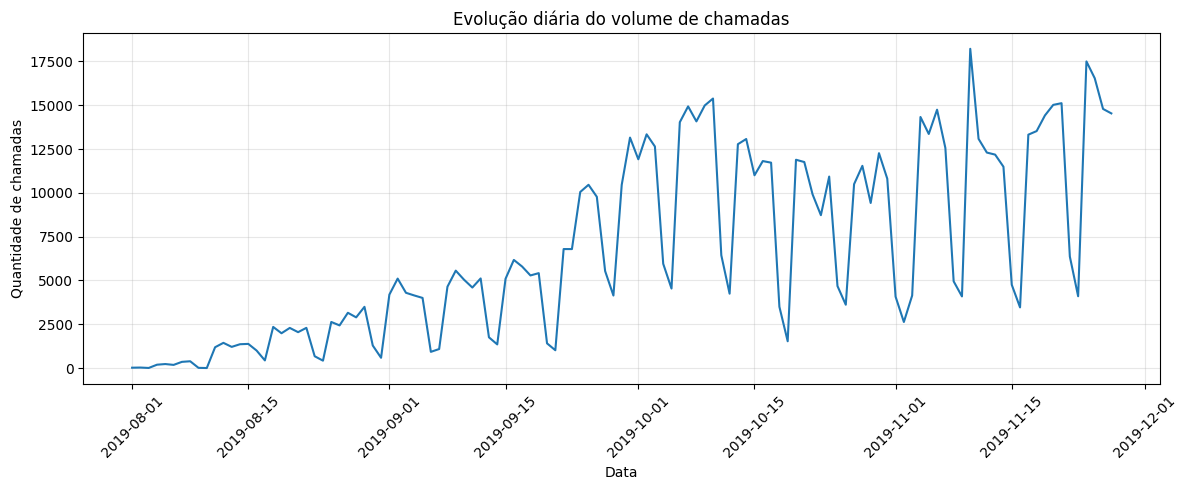

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    chamadas_por_dia.index,
    chamadas_por_dia.values
)

plt.title('Evolução diária do volume de chamadas')
plt.xlabel('Data')
plt.ylabel('Quantidade de chamadas')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretação da evolução diária das chamadas**

Foram identificados 119 dias com registros, totalizando 806.709 chamadas após a remoção das duplicatas.

O gráfico apresenta uma tendência geral de crescimento do volume de chamadas entre agosto e novembro de 2019, com oscilações frequentes ao longo do período.

Observam-se quedas recorrentes no volume diário, sugerindo um possível padrão semanal de atividade. Entretanto, essa hipótese ainda não foi verificada por dia da semana.

Os resultados indicam que a demanda por atendimento não foi constante durante o período analisado, aspecto importante para contextualizar a avaliação de eficiência dos operadores.

In [28]:
ordem_dias = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

media_por_dia_semana = (
    chamadas_por_dia
    .groupby(pd.to_datetime(chamadas_por_dia.index).day_name())
    .mean()
    .reindex(ordem_dias)
)

media_por_dia_semana.index = [
    'Segunda', 'Terça', 'Quarta',
    'Quinta', 'Sexta', 'Sábado', 'Domingo'
]

media_por_dia_semana.round(2)

Segunda    8921.35
Terça      8424.59
Quarta     8750.41
Quinta     7797.00
Sexta      3138.18
Sábado     2191.47
Domingo    8230.47
Name: calls_count, dtype: float64

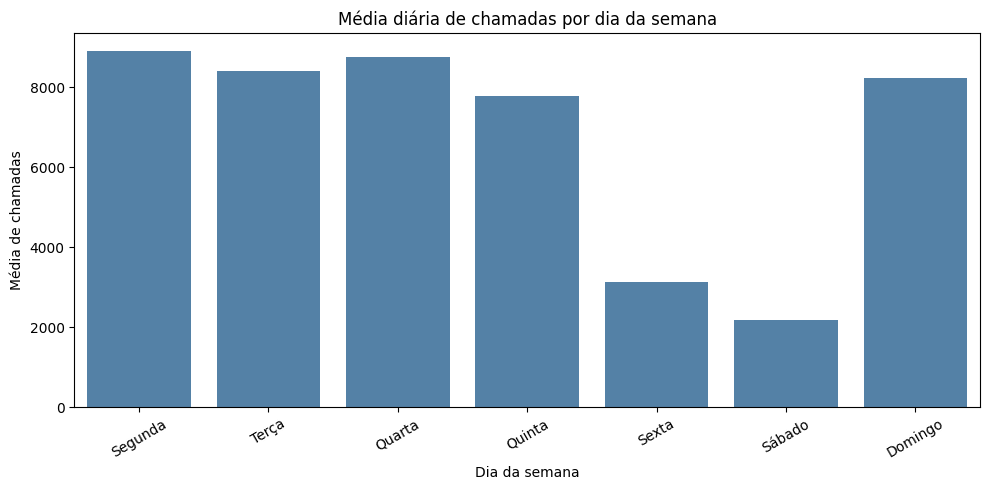

In [29]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=media_por_dia_semana.index,
    y=media_por_dia_semana.values,
    color='steelblue'
)

plt.title('Média diária de chamadas por dia da semana')
plt.xlabel('Dia da semana')
plt.ylabel('Média de chamadas')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Conclusão da análise temporal**

A análise identificou 119 dias com registros, totalizando 806.709 chamadas após a remoção das duplicatas.

O volume diário apresentou uma tendência geral de crescimento entre agosto e novembro de 2019, acompanhada de oscilações frequentes.

A análise por dia da semana confirmou diferenças importantes na demanda. A segunda-feira apresentou a maior média diária, com aproximadamente 8.921 chamadas, enquanto o sábado registrou a menor, com cerca de 2.191 chamadas.

Também foi observada uma redução expressiva nas sextas-feiras, seguida de recuperação aos domingos.

Essas variações devem ser consideradas na avaliação dos operadores, pois diferenças no volume de chamadas podem influenciar os indicadores de eficiência.

### 2.2 Direção das chamadas

Nesta seção, será analisada a distribuição das chamadas de entrada (`in`) e de saída (`out`).

O objetivo é compreender a participação de cada direção no volume total de chamadas, utilizando a soma da coluna `calls_count`, já que cada registro pode representar múltiplas chamadas.

Essa análise ajudará a contextualizar os indicadores de eficiência dos operadores nas etapas seguintes.

In [30]:
chamadas_por_direcao = (
    dados.groupby('direction')['calls_count']
    .sum()
)

percentual_por_direcao = (
    chamadas_por_direcao / chamadas_por_direcao.sum() * 100
)

resultado_direcao = pd.DataFrame({
    'Quantidade de chamadas': chamadas_por_direcao,
    'Percentual (%)': percentual_por_direcao.round(2)
})

resultado_direcao

,Quantidade de chamadas,Percentual (%)
direction,,
in,197845,24.52
out,608864,75.48


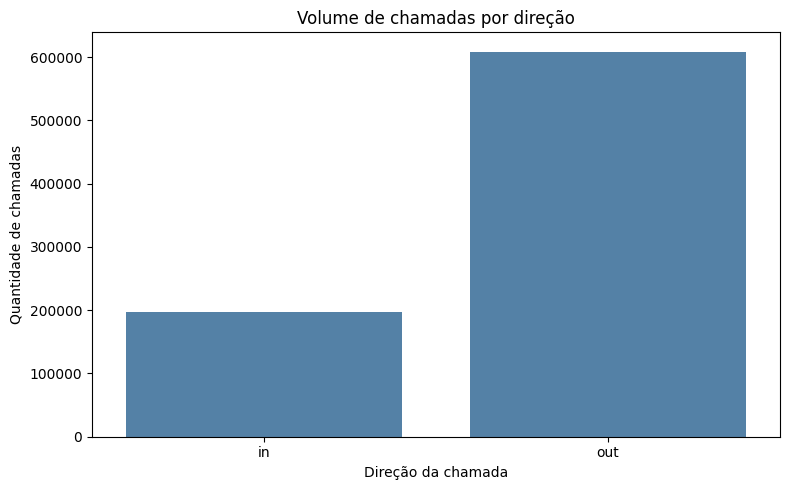

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=chamadas_por_direcao.index,
    y=chamadas_por_direcao.values,
    color='steelblue'
)

plt.title('Volume de chamadas por direção')
plt.xlabel('Direção da chamada')
plt.ylabel('Quantidade de chamadas')
plt.tight_layout()
plt.show()

**Conclusão da análise da direção das chamadas**

Após a remoção das duplicatas, foram contabilizadas 806.709 chamadas.

Desse total, 197.845 (24,52%) correspondem a chamadas de entrada (`in`), enquanto 608.864 (75,48%) são chamadas de saída (`out`).

O gráfico evidencia a predominância das chamadas de saída, cujo volume é aproximadamente três vezes maior que o das chamadas de entrada.

Essa distribuição será considerada nas próximas etapas, pois a avaliação da eficiência dos operadores deverá utilizar indicadores específicos para cada tipo de chamada.

### 2.3 Análise das chamadas perdidas

Nesta seção, será investigada a distribuição das chamadas perdidas, considerando a direção das chamadas (`in` e `out`).

A análise utilizará a coluna `is_missed_call` para identificar os registros marcados como perdidos e a soma de `calls_count` para contabilizar o volume de chamadas.

Será dada atenção especial às chamadas perdidas de entrada, pois elas são relevantes para avaliar a eficiência dos operadores no atendimento de chamadas recebidas.

In [32]:
chamadas_perdidas_direcao = pd.pivot_table(
    dados,
    index='direction',
    columns='is_missed_call',
    values='calls_count',
    aggfunc='sum',
    fill_value=0
)

chamadas_perdidas_direcao.columns = [
    'Não perdidas', 'Perdidas'
]

chamadas_perdidas_direcao['Total'] = (
    chamadas_perdidas_direcao['Não perdidas']
    + chamadas_perdidas_direcao['Perdidas']
)

chamadas_perdidas_direcao['Taxa de perdidas (%)'] = (
    chamadas_perdidas_direcao['Perdidas']
    / chamadas_perdidas_direcao['Total'] * 100
).round(2)

chamadas_perdidas_direcao

,Não perdidas,Perdidas,Total,Taxa de perdidas (%)
direction,,,,
in,93522,104323,197845,52.73
out,337269,271595,608864,44.61


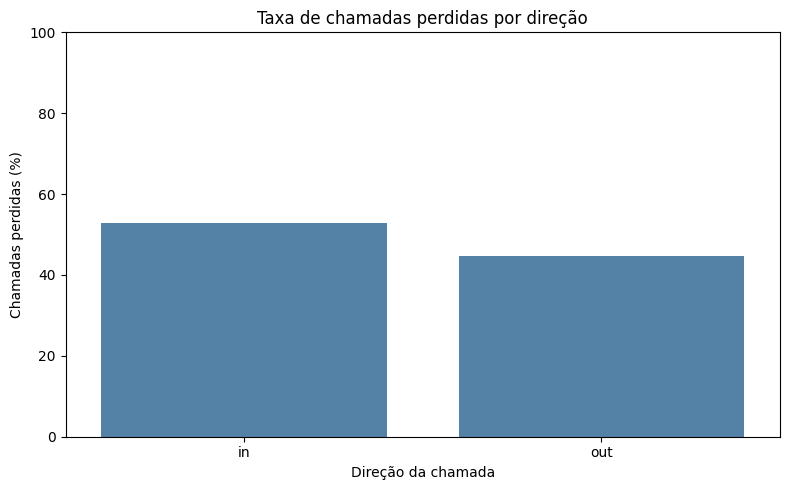

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=chamadas_perdidas_direcao.index,
    y=chamadas_perdidas_direcao['Taxa de perdidas (%)'],
    color='steelblue'
)

plt.title('Taxa de chamadas perdidas por direção')
plt.xlabel('Direção da chamada')
plt.ylabel('Chamadas perdidas (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [34]:
entradas_perdidas = dados[
    (dados['direction'] == 'in') &
    (dados['is_missed_call'] == True)
]

perdidas_por_identificacao = (
    entradas_perdidas
    .groupby(entradas_perdidas['operator_id'].notna())['calls_count']
    .sum()
)

perdidas_por_identificacao.index = [
    'Sem operador identificado',
    'Com operador identificado'
]

perdidas_por_identificacao

Sem operador identificado    103397
Com operador identificado       926
Name: calls_count, dtype: int64

**Conclusão da análise das chamadas perdidas**

Foram identificadas 104.323 chamadas perdidas de entrada, correspondentes a 52,73% do volume de chamadas recebidas.

Entretanto, 103.397 dessas chamadas (99,11%) estão em registros sem operador identificado. Apenas 926 chamadas perdidas de entrada (0,89%) possuem identificação de operador.

Esse resultado representa uma limitação importante para a análise de eficiência individual. A taxa geral de chamadas perdidas não pode ser atribuída diretamente aos operadores.

Nas próximas etapas, os indicadores individuais serão calculados apenas para registros com `operator_id` identificado, deixando explícita essa limitação.

A ausência de identificação não permite concluir por que as chamadas foram perdidas.

### 2.4 Atividade dos operadores

Nesta seção, será analisada a distribuição do volume de chamadas entre os operadores identificados na base de dados.

A análise considerará apenas registros com `operator_id` preenchido e utilizará a soma de `calls_count` para representar a quantidade de chamadas.

O objetivo é identificar diferenças na atividade dos operadores e compreender como o volume de trabalho está distribuído, sem considerar automaticamente um baixo volume como sinal de ineficiência.

In [35]:
dados_operadores = dados.dropna(subset=['operator_id']).copy()

total_operadores = dados_operadores['operator_id'].nunique()

volume_operadores = (
    dados_operadores.groupby('operator_id')['calls_count']
    .sum()
    .sort_values(ascending=False)
)

print('Quantidade de operadores identificados:', total_operadores)
print('Total de chamadas com operador identificado:', volume_operadores.sum())

volume_operadores.head(10)

Quantidade de operadores identificados: 1092
Total de chamadas com operador identificado: 702145


operator_id
885890.0    60221
885876.0    59429
929428.0    23754
925922.0    20021
908640.0    14239
929426.0    11189
879898.0     7313
945286.0     6880
945302.0     6138
893804.0     5846
Name: calls_count, dtype: int64

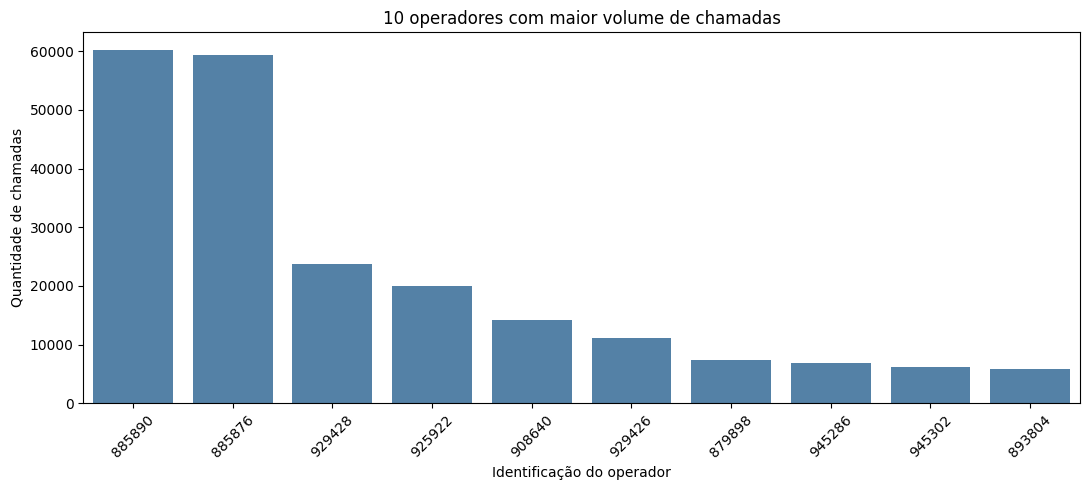

In [36]:
plt.figure(figsize=(11, 5))

sns.barplot(
    x=volume_operadores.head(10).index.astype(int).astype(str),
    y=volume_operadores.head(10).values,
    color='steelblue'
)

plt.title('10 operadores com maior volume de chamadas')
plt.xlabel('Identificação do operador')
plt.ylabel('Quantidade de chamadas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Conclusão da análise da atividade dos operadores**

Foram identificados 1.092 operadores distintos, associados a um total de 702.145 chamadas.

A análise dos 10 operadores com maior volume revelou diferenças expressivas na quantidade de chamadas registradas.

Os operadores `885890` e `885876` apresentaram os maiores volumes, com 60.221 e 59.429 chamadas, respectivamente.

Esses resultados indicam uma distribuição desigual da atividade entre os operadores identificados.

Entretanto, o volume de chamadas isoladamente não é suficiente para determinar a eficiência individual. Nas próximas etapas, serão considerados indicadores específicos de desempenho, levando em conta as características das chamadas e as limitações dos dados disponíveis.

### 2.5 Tempo de duração e espera das chamadas

Nesta seção, serão analisadas as durações das chamadas e os tempos de espera registrados na base de dados.

O tempo de espera será estimado pela diferença entre `total_call_duration` e `call_duration`.

Como cada registro pode representar múltiplas chamadas, a interpretação das durações levará em consideração a coluna `calls_count`.

Essa análise ajudará a compreender o comportamento dos tempos registrados antes do cálculo dos indicadores de eficiência dos operadores.

In [37]:
dados['tempo_espera'] = (
    dados['total_call_duration'] - dados['call_duration']
)

print('Tempo de espera negativo:',
      (dados['tempo_espera'] < 0).sum())

print('Tempo total de espera registrado:',
      dados['tempo_espera'].sum())

dados[['call_duration', 'total_call_duration', 'tempo_espera']].head()

Tempo de espera negativo: 0
Tempo total de espera registrado: 14224110


,call_duration,total_call_duration,tempo_espera
0,0,4,4
1,0,5,5
2,0,1,1
3,10,18,8
4,0,25,25


In [38]:
resumo_tempos = pd.DataFrame({
    'Indicador': [
        'Duração média da conversa',
        'Tempo médio de espera',
        'Duração média total'
    ],
    'Segundos por chamada': [
        dados['call_duration'].sum() / dados['calls_count'].sum(),
        dados['tempo_espera'].sum() / dados['calls_count'].sum(),
        dados['total_call_duration'].sum() / dados['calls_count'].sum()
    ]
})

resumo_tempos['Segundos por chamada'] = (
    resumo_tempos['Segundos por chamada'].round(2)
)

resumo_tempos

,Indicador,Segundos por chamada
0,Duração média da conversa,52.62
1,Tempo médio de espera,17.63
2,Duração média total,70.25


In [39]:
tempos_por_direcao = (
    dados.groupby('direction')[
        ['calls_count', 'call_duration',
         'tempo_espera', 'total_call_duration']
    ]
    .sum()
)

for coluna in ['call_duration', 'tempo_espera', 'total_call_duration']:
    tempos_por_direcao[coluna] = (
        tempos_por_direcao[coluna]
        / tempos_por_direcao['calls_count']
    ).round(2)

tempos_por_direcao

,calls_count,call_duration,tempo_espera,total_call_duration
direction,,,,
in,197845,49.77,12.62,62.39
out,608864,53.55,19.26,72.81


**Conclusão da análise dos tempos das chamadas**

A análise não identificou tempos de espera negativos, confirmando que a diferença entre `total_call_duration` e `call_duration` é não negativa em todos os registros.

Considerando as 806.709 chamadas, foram obtidas as seguintes médias gerais: 52,62 segundos de conversa, 17,63 segundos de espera estimada e 70,25 segundos de duração total.

Na comparação por direção, as chamadas de entrada apresentaram duração média de conversa de 49,77 segundos e espera estimada de 12,62 segundos. Já as chamadas de saída apresentaram médias de 53,55 e 19,26 segundos, respectivamente.

Esses resultados foram calculados dividindo os tempos acumulados pela soma de `calls_count`, pois cada registro pode representar múltiplas chamadas.

As diferenças observadas devem ser interpretadas com cautela, especialmente porque os tempos de chamadas de saída podem incluir etapas de conexão e discagem.

Na avaliação de eficiência dos operadores, serão utilizados indicadores específicos para as chamadas de entrada e consideradas as limitações dos registros disponíveis.

## 3. Cálculo dos indicadores de eficiência dos operadores

Nesta etapa, serão calculados indicadores para avaliar a eficiência dos operadores da CallMeMaybe.

Serão considerados a taxa de chamadas perdidas de entrada, o tempo médio de espera nas chamadas recebidas e o volume de chamadas de saída.

Os cálculos utilizarão a soma de `calls_count`, quando necessário, e considerarão apenas os registros com `operator_id` identificado para a avaliação individual.

Os indicadores serão interpretados com cautela, levando em conta as limitações dos dados e as diferenças de atividade entre os operadores.

### 3.1 Preparação dos dados por operador

Nesta seção, serão organizados os registros com `operator_id` identificado para o cálculo dos indicadores individuais de eficiência.

As chamadas de entrada e saída serão analisadas separadamente, respeitando as características de cada indicador.

Os registros sem identificação de operador permanecerão na base geral, mas não serão utilizados para atribuir desempenho a operadores específicos.

In [40]:
operadores_entrada = dados_operadores[
    dados_operadores['direction'] == 'in'
].copy()

operadores_saida = dados_operadores[
    dados_operadores['direction'] == 'out'
].copy()

print('Operadores com chamadas de entrada:',
      operadores_entrada['operator_id'].nunique())

print('Operadores com chamadas de saída:',
      operadores_saida['operator_id'].nunique())

print('Chamadas de entrada com operador identificado:',
      operadores_entrada['calls_count'].sum())

print('Chamadas de saída com operador identificado:',
      operadores_saida['calls_count'].sum())

Operadores com chamadas de entrada: 754
Operadores com chamadas de saída: 882
Chamadas de entrada com operador identificado: 93802
Chamadas de saída com operador identificado: 608343


In [41]:
resumo_operadores = pd.DataFrame({
    'Direção': ['Entrada', 'Saída'],
    'Operadores únicos': [
        operadores_entrada['operator_id'].nunique(),
        operadores_saida['operator_id'].nunique()
    ],
    'Total de chamadas': [
        operadores_entrada['calls_count'].sum(),
        operadores_saida['calls_count'].sum()
    ]
})

display(resumo_operadores)

,Direção,Operadores únicos,Total de chamadas
0,Entrada,754,93802
1,Saída,882,608343


**Conclusão da preparação dos dados por operador**

Foram identificados 754 operadores com chamadas de entrada, totalizando 93.802 chamadas, e 882 operadores com chamadas de saída, totalizando 608.343 chamadas.

Esses grupos não são necessariamente exclusivos, pois um operador pode realizar e receber chamadas.

A análise individual considera apenas chamadas com operador identificado. Essa limitação é especialmente importante para as chamadas perdidas de entrada, já que a maioria delas não possui identificação de operador.

Com os dados separados por direção, podemos calcular os indicadores de eficiência sem misturar atividades diferentes.

### 3.2 Taxa de chamadas perdidas de entrada

Nesta seção, será calculada a proporção de chamadas de entrada perdidas por operador.

A taxa será obtida dividindo a quantidade de chamadas perdidas de entrada pelo total de chamadas de entrada atribuídas a cada operador, utilizando `calls_count` como medida de volume.

Como a maioria das chamadas perdidas de entrada não possui `operator_id`, esse indicador será interpretado apenas como a taxa observada entre as chamadas com operador identificado, sem representar necessariamente a taxa real de perdas de cada operador.

In [42]:
total_entrada = operadores_entrada.groupby('operator_id')['calls_count'].sum()

perdidas_entrada = (
    operadores_entrada[operadores_entrada['is_missed_call'] == True]
    .groupby('operator_id')['calls_count']
    .sum()
)

taxa_perdidas_operador = pd.DataFrame({
    'total_entrada': total_entrada,
    'perdidas_entrada': perdidas_entrada
}).fillna(0)

taxa_perdidas_operador['taxa_perdidas_pct'] = (
    taxa_perdidas_operador['perdidas_entrada']
    / taxa_perdidas_operador['total_entrada'] * 100
)

display(taxa_perdidas_operador.head(10))

,total_entrada,perdidas_entrada,taxa_perdidas_pct
operator_id,,,
879896.0,58,0.0,0.000000
879898.0,104,0.0,0.000000
880020.0,7,0.0,0.000000
880022.0,8,0.0,0.000000
880026.0,24,0.0,0.000000
880028.0,63,0.0,0.000000
882476.0,3,0.0,0.000000
882478.0,3,0.0,0.000000
882680.0,99,3.0,3.030303


In [43]:
print('Operadores analisados:', len(taxa_perdidas_operador))

print('Operadores com chamadas perdidas:',
      (taxa_perdidas_operador['perdidas_entrada'] > 0).sum())

display(taxa_perdidas_operador['taxa_perdidas_pct'].describe().round(2))

Operadores analisados: 754
Operadores com chamadas perdidas: 239


count    754.00
mean       1.76
std        6.53
min        0.00
25%        0.00
50%        0.00
75%        0.67
max      100.00
Name: taxa_perdidas_pct, dtype: float64

In [44]:
display(
    taxa_perdidas_operador
    .sort_values('taxa_perdidas_pct', ascending=False)
    .head(10)
    .round(2)
)

,total_entrada,perdidas_entrada,taxa_perdidas_pct
operator_id,,,
948756.0,1,1.0,100.00
904344.0,4,3.0,75.00
913886.0,2,1.0,50.00
906392.0,18,7.0,38.89
957922.0,3,1.0,33.33
937432.0,3,1.0,33.33
934098.0,6,2.0,33.33
897872.0,3,1.0,33.33
906412.0,26,7.0,26.92


In [45]:
display(taxa_perdidas_operador['total_entrada'].describe().round(2))

print('Operadores com menos de 10 chamadas:',
      (taxa_perdidas_operador['total_entrada'] < 10).sum())

print('Operadores com pelo menos 30 chamadas:',
      (taxa_perdidas_operador['total_entrada'] >= 30).sum())

count     754.00
mean      124.41
std       356.45
min         1.00
25%         4.00
50%        17.00
75%        78.75
max      4766.00
Name: total_entrada, dtype: float64

Operadores com menos de 10 chamadas: 308
Operadores com pelo menos 30 chamadas: 296


**Conclusão da análise da taxa de chamadas perdidas de entrada**

Entre os 754 operadores com chamadas de entrada identificadas, 239 apresentaram pelo menos uma chamada perdida. A taxa média individual de perdas foi de 1,76%, enquanto a mediana foi de 0%.

Observou-se uma grande diferença no volume de chamadas entre os operadores. Dos 754 analisados, 308 receberam menos de 10 chamadas, e apenas 296 receberam pelo menos 30 chamadas.

Assim, taxas elevadas de perdas devem ser interpretadas com cautela, especialmente quando calculadas a partir de poucas chamadas.

Além disso, como a maioria das chamadas perdidas de entrada não possui identificação de operador, os resultados individuais não representam necessariamente o desempenho real de cada profissional.

Na etapa de classificação, será necessário considerar o volume de chamadas e essas limitações antes de identificar possíveis operadores menos eficientes.

### 3.3 Tempo médio de espera nas chamadas de entrada

Nesta seção, será calculado o tempo médio estimado de espera das chamadas de entrada por operador.

O tempo de espera será obtido pela diferença entre `total_call_duration` e `call_duration`. Para calcular a média por chamada, a soma desse tempo será dividida pela soma de `calls_count` de cada operador.

Serão considerados apenas os registros de chamadas de entrada com `operator_id` identificado.

Esse indicador será interpretado com cautela, pois o tempo estimado pode incluir diferentes etapas do atendimento e não representa necessariamente apenas o tempo aguardando resposta.

In [46]:
operadores_entrada['tempo_espera'] = (
    operadores_entrada['total_call_duration']
    - operadores_entrada['call_duration']
)

espera_operadores = (
    operadores_entrada.groupby('operator_id')[
        ['tempo_espera', 'calls_count']
    ].sum()
)

espera_operadores['tempo_medio_espera_seg'] = (
    espera_operadores['tempo_espera']
    / espera_operadores['calls_count']
)

display(espera_operadores.head(10).round(2))

,tempo_espera,calls_count,tempo_medio_espera_seg
operator_id,,,
879896.0,574,58,9.90
879898.0,1680,104,16.15
880020.0,54,7,7.71
880022.0,112,8,14.00
880026.0,143,24,5.96
880028.0,343,63,5.44
882476.0,95,3,31.67
882478.0,76,3,25.33
882680.0,1591,99,16.07


In [47]:
display(
    espera_operadores['tempo_medio_espera_seg']
    .describe()
    .round(2)
)

print(
    'Tempo médio geral de espera nas chamadas de entrada identificadas:',
    round(
        espera_operadores['tempo_espera'].sum()
        / espera_operadores['calls_count'].sum(),
        2
    ),
    'segundos'
)

count    754.00
mean      17.49
std       12.17
min        0.68
25%        9.40
50%       14.43
75%       21.84
max      115.50
Name: tempo_medio_espera_seg, dtype: float64

Tempo médio geral de espera nas chamadas de entrada identificadas: 13.15 segundos


**Conclusão da análise do tempo médio de espera nas chamadas de entrada**

Foram analisados 754 operadores com chamadas de entrada identificadas. A média dos tempos médios individuais foi de 17,49 segundos, enquanto a mediana foi de 14,43 segundos.

Considerando o volume de chamadas de cada operador, o tempo médio geral estimado de espera foi de 13,15 segundos por chamada.

Os tempos médios individuais variaram de 0,68 a 115,50 segundos, indicando diferenças relevantes entre os operadores.

Entretanto, valores elevados não devem ser interpretados isoladamente como sinal de ineficiência, especialmente quando o operador possui poucas chamadas registradas.

Na etapa de classificação, o tempo médio de espera será considerado em conjunto com o volume de chamadas e as limitações dos dados.

### 3.4 Volume de chamadas de saída

Nesta seção, será analisado o volume de chamadas de saída realizadas por operador.

O indicador será calculado pela soma de `calls_count` dos registros com `direction` igual a `out` e `operator_id` identificado.

Serão considerados apenas os operadores que possuem chamadas de saída registradas, evitando comparar profissionais que desempenham exclusivamente atividades de entrada.

O volume será interpretado com cautela, pois diferenças no período de atividade e na distribuição das tarefas podem influenciar a quantidade de chamadas realizadas.

In [48]:
volume_saida_operador = (
    operadores_saida.groupby('operator_id')['calls_count']
    .sum()
    .sort_values(ascending=False)
    .to_frame(name='total_saida')
)

display(volume_saida_operador.head(10))

,total_saida
operator_id,
885890.0,58977
885876.0,58437
929428.0,23754
925922.0,19603
908640.0,14239
929426.0,11189
879898.0,7209
945286.0,6880
945302.0,6138


In [49]:
display(volume_saida_operador['total_saida'].describe().round(2))

print('Operadores com chamadas de saída:',
      len(volume_saida_operador))

print('Operadores com menos de 10 chamadas de saída:',
      (volume_saida_operador['total_saida'] < 10).sum())

print('Operadores com pelo menos 30 chamadas de saída:',
      (volume_saida_operador['total_saida'] >= 30).sum())

count      882.00
mean       689.73
std       3122.95
min          1.00
25%         11.00
50%         90.00
75%        597.25
max      58977.00
Name: total_saida, dtype: float64

Operadores com chamadas de saída: 882
Operadores com menos de 10 chamadas de saída: 200
Operadores com pelo menos 30 chamadas de saída: 561


In [50]:
operadores_saida['dia'] = operadores_saida['date'].dt.date

atividade_saida = (
    operadores_saida.groupby('operator_id')
    .agg(
        dias_ativos=('dia', 'nunique'),
        primeira_chamada=('date', 'min'),
        ultima_chamada=('date', 'max')
    )
)

atividade_saida['chamadas_por_dia_ativo'] = (
    volume_saida_operador['total_saida']
    / atividade_saida['dias_ativos']
)

display(atividade_saida.head(10).round(2))

,dias_ativos,primeira_chamada,ultima_chamada,chamadas_por_dia_ativo
operator_id,,,,
879896.0,49,2019-08-01 21:00:00+00:00,2019-11-24 21:00:00+00:00,17.80
879898.0,82,2019-08-01 21:00:00+00:00,2019-11-27 21:00:00+00:00,87.91
880020.0,7,2019-08-04 21:00:00+00:00,2019-10-02 21:00:00+00:00,5.43
880022.0,36,2019-08-04 21:00:00+00:00,2019-11-26 21:00:00+00:00,5.25
880026.0,77,2019-08-06 21:00:00+00:00,2019-11-27 21:00:00+00:00,28.68
880028.0,78,2019-08-06 21:00:00+00:00,2019-11-27 21:00:00+00:00,32.01
880240.0,7,2019-08-01 21:00:00+00:00,2019-08-29 21:00:00+00:00,6.71
881278.0,5,2019-08-05 21:00:00+00:00,2019-11-24 21:00:00+00:00,4.00
882478.0,1,2019-08-06 21:00:00+00:00,2019-08-06 21:00:00+00:00,1.00


In [51]:
display(
    atividade_saida['chamadas_por_dia_ativo']
    .describe()
    .round(2)
)

print(
    'Operadores com apenas 1 dia de atividade:',
    (atividade_saida['dias_ativos'] == 1).sum()
)

print(
    'Operadores com pelo menos 10 dias de atividade:',
    (atividade_saida['dias_ativos'] >= 10).sum()
)

count    882.00
mean      29.39
std       67.05
min        1.00
25%        2.67
50%        6.59
75%       29.00
max      816.79
Name: chamadas_por_dia_ativo, dtype: float64

Operadores com apenas 1 dia de atividade: 125
Operadores com pelo menos 10 dias de atividade: 475


**Conclusão da análise do volume de chamadas de saída**

Foram identificados 882 operadores com chamadas de saída registradas. O volume médio foi de 689,73 chamadas por operador, enquanto a mediana foi de 90 chamadas, indicando uma distribuição bastante desigual.

Entre esses operadores, 200 realizaram menos de 10 chamadas de saída e 561 realizaram pelo menos 30 chamadas.

Ao considerar os dias com atividade registrada, a média individual foi de 29,39 chamadas por dia ativo, enquanto a mediana foi de 6,59. Além disso, 125 operadores apresentaram apenas um dia com chamadas de saída, e 475 tiveram pelo menos 10 dias de atividade.

Esses resultados mostram que o volume total de chamadas, isoladamente, não é suficiente para avaliar a eficiência. A quantidade de dias com atividade deve ser considerada para reduzir comparações inadequadas entre operadores.

Na etapa de classificação, o volume de chamadas de saída será analisado em conjunto com a atividade registrada, sem presumir que os dias ativos correspondam à jornada completa de trabalho.

In [52]:
indicadores_operadores = (
    taxa_perdidas_operador[
        ['total_entrada', 'perdidas_entrada', 'taxa_perdidas_pct']
    ]
    .join(
        espera_operadores[['tempo_medio_espera_seg']],
        how='outer'
    )
    .join(
        volume_saida_operador[['total_saida']],
        how='outer'
    )
    .join(
        atividade_saida[['dias_ativos', 'chamadas_por_dia_ativo']],
        how='outer'
    )
)

print('Total de operadores na tabela:', len(indicadores_operadores))

display(indicadores_operadores.head(10).round(2))

Total de operadores na tabela: 1092


,total_entrada,perdidas_entrada,taxa_perdidas_pct,tempo_medio_espera_seg,total_saida,dias_ativos,chamadas_por_dia_ativo
operator_id,,,,,,,
879896.0,58.0,0.0,0.0,9.90,872.0,49.0,17.80
879898.0,104.0,0.0,0.0,16.15,7209.0,82.0,87.91
880020.0,7.0,0.0,0.0,7.71,38.0,7.0,5.43
880022.0,8.0,0.0,0.0,14.00,189.0,36.0,5.25
880026.0,24.0,0.0,0.0,5.96,2208.0,77.0,28.68
880028.0,63.0,0.0,0.0,5.44,2497.0,78.0,32.01
880240.0,NaN,NaN,NaN,NaN,47.0,7.0,6.71
881278.0,NaN,NaN,NaN,NaN,20.0,5.0,4.00
882476.0,3.0,0.0,0.0,31.67,NaN,NaN,NaN


**Conclusão do cálculo dos indicadores de eficiência dos operadores**

Foram calculados e consolidados os principais indicadores de eficiência dos operadores da CallMeMaybe: taxa de chamadas perdidas de entrada, tempo médio estimado de espera nas chamadas recebidas e volume de chamadas de saída.

A tabela consolidada reúne 1.092 operadores identificados, incluindo profissionais que realizaram chamadas de entrada, de saída ou ambas.

A análise mostrou diferenças relevantes no volume de chamadas e nos períodos de atividade. Por isso, os indicadores não devem ser interpretados isoladamente, especialmente quando há poucas chamadas registradas.

Também foi identificada uma limitação importante: a maioria das chamadas perdidas de entrada não possui identificação de operador, o que restringe a avaliação individual desse indicador.

Os valores ausentes foram preservados, pois representam atividades sem registros para determinado operador, e não necessariamente desempenho igual a zero.

Na próxima etapa, serão definidos critérios de comparação para identificar possíveis operadores menos eficientes, considerando os indicadores disponíveis, o volume de chamadas e as limitações dos dados.

## 4. Identificação dos operadores menos eficientes

Nesta etapa, serão definidos e aplicados critérios para identificar possíveis operadores menos eficientes, utilizando os indicadores calculados anteriormente.

A avaliação considerará a taxa de chamadas perdidas de entrada, o tempo médio estimado de espera e o volume de chamadas de saída por dia ativo.

Para evitar classificações inadequadas, serão consideradas as diferenças no volume de chamadas, no período de atividade e na disponibilidade dos dados.

Os critérios serão definidos antes da classificação dos operadores, evitando utilizar os próprios resultados para justificar a formação dos grupos que serão comparados posteriormente nos testes estatísticos.

### 4.1 Definição dos critérios de classificação

A identificação dos operadores potencialmente menos eficientes será realizada separadamente para chamadas de entrada e de saída.

Para os operadores de entrada, serão considerados a taxa de chamadas perdidas e o tempo médio estimado de espera. Para os operadores de saída, será analisada a quantidade de chamadas por dia ativo.

Antes da classificação, serão estabelecidos critérios mínimos de volume e atividade para reduzir a influência de resultados calculados com poucas chamadas ou poucos dias registrados.

Os indicadores serão comparados apenas entre operadores com dados suficientes para cada análise. A ausência de registros de determinada atividade não será interpretada como ineficiência.

Os resultados representarão possíveis sinais de menor eficiência, e não uma avaliação definitiva do desempenho profissional. Também serão consideradas as limitações de identificação das chamadas perdidas de entrada.

In [53]:
min_chamadas_entrada = 30
min_dias_saida = 10

entrada_elegiveis = taxa_perdidas_operador[
    taxa_perdidas_operador['total_entrada'] >= min_chamadas_entrada
].copy()

saida_elegiveis = atividade_saida[
    atividade_saida['dias_ativos'] >= min_dias_saida
].copy()

print('Operadores elegíveis para análise de entrada:', len(entrada_elegiveis))
print('Operadores elegíveis para análise de saída:', len(saida_elegiveis))

print('Operadores excluídos da comparação de entrada:',
      len(taxa_perdidas_operador) - len(entrada_elegiveis))

print('Operadores excluídos da comparação de saída:',
      len(atividade_saida) - len(saida_elegiveis))

Operadores elegíveis para análise de entrada: 296
Operadores elegíveis para análise de saída: 475
Operadores excluídos da comparação de entrada: 458
Operadores excluídos da comparação de saída: 407


In [54]:
limite_perdas = entrada_elegiveis['taxa_perdidas_pct'].quantile(0.75)

limite_espera = espera_operadores.loc[
    entrada_elegiveis.index, 'tempo_medio_espera_seg'
].quantile(0.75)

limite_saida = saida_elegiveis['chamadas_por_dia_ativo'].quantile(0.25)

print('Limite da taxa de perdas (%):', round(limite_perdas, 2))
print('Limite do tempo médio de espera (segundos):', round(limite_espera, 2))
print('Limite de chamadas por dia ativo:', round(limite_saida, 2))

Limite da taxa de perdas (%): 1.63
Limite do tempo médio de espera (segundos): 18.95
Limite de chamadas por dia ativo: 5.26


**Conclusão da definição dos critérios de classificação**

Foram definidos critérios mínimos de atividade para tornar a comparação entre operadores mais consistente. Na análise de entrada, serão considerados os 296 operadores com pelo menos 30 chamadas recebidas. Na análise de saída, serão considerados os 475 operadores com pelo menos 10 dias de atividade registrada.

Para identificar possíveis sinais de menor eficiência, foram utilizados limites baseados nos quartis dos indicadores dos operadores elegíveis.

Nas chamadas de entrada, serão considerados sinais de atenção taxas de perdas superiores ao terceiro quartil (aproximadamente 1,63%) e tempos médios de espera superiores ao terceiro quartil (aproximadamente 18,95 segundos).

Nas chamadas de saída, serão considerados sinais de atenção volumes inferiores ao primeiro quartil (aproximadamente 5,26 chamadas por dia ativo).

Esses limites representam referências relativas aos grupos analisados, e não padrões oficiais de desempenho. Os operadores com atividade insuficiente não serão classificados como ineficientes.

A classificação também deverá considerar a ausência de identificação da maioria das chamadas perdidas de entrada e não será utilizada, isoladamente, como prova estatística de diferenças de desempenho.

### 4.2 Avaliação dos operadores de entrada

Nesta seção, serão avaliados os operadores com pelo menos 30 chamadas de entrada registradas.

Serão utilizados dois indicadores: a taxa de chamadas perdidas de entrada e o tempo médio estimado de espera.

Serão sinalizados para atenção os operadores que apresentarem taxa de perdas acima do terceiro quartil ou tempo médio de espera acima do terceiro quartil dos operadores elegíveis.

Esses sinais serão analisados separadamente e em conjunto, sem considerar automaticamente os operadores sinalizados como ineficientes.

A interpretação levará em conta o volume de chamadas e a limitação de identificação das chamadas perdidas de entrada.

In [55]:
avaliacao_entrada = entrada_elegiveis.join(
    espera_operadores[['tempo_medio_espera_seg']]
)

avaliacao_entrada['alerta_perdas'] = (
    avaliacao_entrada['taxa_perdidas_pct'] > limite_perdas
)

avaliacao_entrada['alerta_espera'] = (
    avaliacao_entrada['tempo_medio_espera_seg'] > limite_espera
)

avaliacao_entrada['total_alertas'] = (
    avaliacao_entrada['alerta_perdas'].astype(int)
    + avaliacao_entrada['alerta_espera'].astype(int)
)

print('Operadores avaliados:', len(avaliacao_entrada))
print('Operadores com alerta de perdas:', avaliacao_entrada['alerta_perdas'].sum())
print('Operadores com alerta de espera:', avaliacao_entrada['alerta_espera'].sum())

display(avaliacao_entrada.head(10).round(2))

Operadores avaliados: 296
Operadores com alerta de perdas: 74
Operadores com alerta de espera: 74


,total_entrada,perdidas_entrada,taxa_perdidas_pct,tempo_medio_espera_seg,alerta_perdas,alerta_espera,total_alertas
operator_id,,,,,,,
879896.0,58,0.0,0.00,9.90,False,False,0
879898.0,104,0.0,0.00,16.15,False,False,0
880028.0,63,0.0,0.00,5.44,False,False,0
882680.0,99,3.0,3.03,16.07,True,False,1
882684.0,613,4.0,0.65,15.54,False,False,0
882686.0,766,6.0,0.78,14.71,False,False,0
882690.0,171,2.0,1.17,41.53,False,True,1
883942.0,77,0.0,0.00,7.05,False,False,0
884408.0,35,4.0,11.43,26.40,True,True,2


In [56]:
display(
    avaliacao_entrada['total_alertas']
    .value_counts()
    .sort_index()
    .rename_axis('Quantidade de alertas')
    .to_frame('Operadores')
)

,Operadores
Quantidade de alertas,
0,175
1,94
2,27


In [57]:
operadores_dois_alertas = (
    avaliacao_entrada[avaliacao_entrada['total_alertas'] == 2]
    .sort_values(
        ['taxa_perdidas_pct', 'tempo_medio_espera_seg'],
        ascending=False
    )
)

display(
    operadores_dois_alertas[
        ['total_entrada', 'taxa_perdidas_pct', 'tempo_medio_espera_seg']
    ].head(10).round(2)
)

,total_entrada,taxa_perdidas_pct,tempo_medio_espera_seg
operator_id,,,
944226.0,180,16.67,42.66
884408.0,35,11.43,26.40
944216.0,235,10.21,35.61
944222.0,185,9.19,33.88
920706.0,68,8.82,23.91
944220.0,265,6.79,36.07
899268.0,31,6.45,20.77
944218.0,245,6.12,36.72
907952.0,51,3.92,20.53


**Conclusão da identificação de operadores com alertas nas chamadas de entrada**

Foram avaliados 296 operadores com pelo menos 30 chamadas de entrada identificadas, considerando a taxa de chamadas perdidas e o tempo médio estimado de espera.

Entre eles, 175 não apresentaram alertas, 94 apresentaram apenas um alerta e 27 apresentaram dois alertas simultaneamente.

Os operadores com dois alertas representam 9,12% do grupo avaliado e merecem atenção prioritária, pois ultrapassaram os limites definidos para os dois indicadores.

Entretanto, esses resultados representam sinais de possível ineficiência, e não uma classificação definitiva. A maioria das chamadas perdidas de entrada não possui operador identificado, e fatores relacionados à distribuição das chamadas também podem influenciar os indicadores.

A análise de chamadas de saída será realizada separadamente, respeitando as diferenças entre as atividades dos operadores.

### 4.3 Identificação de operadores com baixo volume de chamadas de saída

Nesta seção, serão identificados operadores com possível baixa atividade nas chamadas de saída.

A comparação utilizará a quantidade média de chamadas por dia com atividade registrada, em vez de considerar apenas o volume total de chamadas.

Para reduzir distorções causadas por períodos muito curtos de observação, será considerado um número mínimo de dias ativos antes da classificação.

Os limites de comparação serão definidos a partir da distribuição dos dados, e os resultados serão interpretados como sinais de possível baixa eficiência, não como conclusões definitivas sobre o desempenho dos operadores.

In [58]:
saida_elegiveis = atividade_saida[
    atividade_saida['dias_ativos'] >= 10
].copy()

limite_saida = saida_elegiveis[
    'chamadas_por_dia_ativo'
].quantile(0.25)

print('Operadores elegíveis:', len(saida_elegiveis))
print('Limite de baixo volume por dia ativo:', round(limite_saida, 2))

display(
    saida_elegiveis['chamadas_por_dia_ativo']
    .describe()
    .round(2)
)

Operadores elegíveis: 475
Limite de baixo volume por dia ativo: 5.26


count    475.00
mean      42.66
std       84.70
min        1.40
25%        5.26
50%       14.10
75%       46.22
max      816.79
Name: chamadas_por_dia_ativo, dtype: float64

In [59]:
avaliacao_saida = saida_elegiveis.join(
    volume_saida_operador[['total_saida']]
)

avaliacao_saida['alerta_baixo_volume'] = (
    avaliacao_saida['chamadas_por_dia_ativo'] < limite_saida
)

print('Operadores avaliados:', len(avaliacao_saida))

print(
    'Operadores com alerta de baixo volume:',
    avaliacao_saida['alerta_baixo_volume'].sum()
)

display(
    avaliacao_saida[
        ['total_saida', 'dias_ativos',
         'chamadas_por_dia_ativo', 'alerta_baixo_volume']
    ]
    .sort_values('chamadas_por_dia_ativo')
    .head(10)
    .round(2)
)

Operadores avaliados: 475
Operadores com alerta de baixo volume: 119


,total_saida,dias_ativos,chamadas_por_dia_ativo,alerta_baixo_volume
operator_id,,,,
924370.0,14,10,1.40,True
904044.0,23,16,1.44,True
900614.0,34,21,1.62,True
937782.0,26,16,1.62,True
905934.0,20,12,1.67,True
924932.0,28,16,1.75,True
893402.0,51,29,1.76,True
940456.0,32,18,1.78,True
893420.0,29,16,1.81,True


**Conclusão da identificação de operadores com baixo volume de chamadas de saída**

Foram avaliados 475 operadores com pelo menos 10 dias de atividade em chamadas de saída.

O limite de baixo volume foi definido pelo primeiro quartil da distribuição, correspondente a aproximadamente 5,26 chamadas por dia ativo.

Entre os operadores avaliados, 119 (25,05%) apresentaram volume médio diário abaixo desse limite, sendo sinalizados para análise adicional.

A utilização de chamadas por dia ativo permite considerar diferenças na frequência de atividade registrada. Entretanto, esse indicador não representa necessariamente a produtividade por hora trabalhada.

Assim, os alertas identificam possíveis situações de baixa atividade, mas não comprovam ineficiência, pois não há informações suficientes sobre jornadas, metas individuais e distribuição das tarefas.

### 4.4 Consolidação dos alertas de eficiência dos operadores

Nesta seção, serão reunidos os alertas identificados nas análises de chamadas de entrada e saída.

Os indicadores serão mantidos separadamente, pois representam atividades diferentes e possuem critérios próprios de avaliação.

Operadores sem atividade registrada em determinada direção não serão considerados ineficientes por esse motivo.

A consolidação permitirá identificar os operadores que apresentam sinais de possível ineficiência, respeitando os critérios mínimos de atividade e as limitações dos dados.

In [60]:
alertas_operadores = pd.DataFrame(
    index=indicadores_operadores.index
)

alertas_operadores['elegivel_entrada'] = (
    alertas_operadores.index.isin(avaliacao_entrada.index)
)

alertas_operadores['elegivel_saida'] = (
    alertas_operadores.index.isin(avaliacao_saida.index)
)

alertas_operadores = alertas_operadores.join(
    avaliacao_entrada[
        ['alerta_perdas', 'alerta_espera']
    ],
    how='left'
)

alertas_operadores = alertas_operadores.join(
    avaliacao_saida[['alerta_baixo_volume']],
    how='left'
)

print('Total de operadores identificados:', len(alertas_operadores))

print(
    'Operadores elegíveis em pelo menos uma análise:',
    (
        alertas_operadores['elegivel_entrada']
        | alertas_operadores['elegivel_saida']
    ).sum()
)

print(
    'Operadores elegíveis nas duas análises:',
    (
        alertas_operadores['elegivel_entrada']
        & alertas_operadores['elegivel_saida']
    ).sum()
)

display(alertas_operadores.head(10))

Total de operadores identificados: 1092
Operadores elegíveis em pelo menos uma análise: 564
Operadores elegíveis nas duas análises: 207


,elegivel_entrada,elegivel_saida,alerta_perdas,alerta_espera,alerta_baixo_volume
operator_id,,,,,
879896.0,True,True,False,False,False
879898.0,True,True,False,False,False
880020.0,False,False,NaN,NaN,NaN
880022.0,False,True,NaN,NaN,True
880026.0,False,True,NaN,NaN,False
880028.0,True,True,False,False,False
880240.0,False,False,NaN,NaN,NaN
881278.0,False,False,NaN,NaN,NaN
882476.0,False,False,NaN,NaN,NaN


In [61]:
alertas_operadores['algum_alerta'] = (
    alertas_operadores[
        ['alerta_perdas', 'alerta_espera', 'alerta_baixo_volume']
    ].eq(True).any(axis=1)
)

elegiveis = (
    alertas_operadores['elegivel_entrada']
    | alertas_operadores['elegivel_saida']
)

print('Operadores elegíveis:', elegiveis.sum())

print(
    'Operadores elegíveis com pelo menos um alerta:',
    (elegiveis & alertas_operadores['algum_alerta']).sum()
)

print(
    'Operadores elegíveis sem alertas:',
    (elegiveis & ~alertas_operadores['algum_alerta']).sum()
)

Operadores elegíveis: 564
Operadores elegíveis com pelo menos um alerta: 214
Operadores elegíveis sem alertas: 350


In [62]:
colunas_alertas = [
    'alerta_perdas',
    'alerta_espera',
    'alerta_baixo_volume'
]

alertas_operadores['total_alertas'] = (
    alertas_operadores[colunas_alertas]
    .eq(True)
    .sum(axis=1)
)

display(
    alertas_operadores.loc[elegiveis, 'total_alertas']
    .value_counts()
    .sort_index()
    .rename_axis('Quantidade de alertas')
    .to_frame('Operadores')
)

,Operadores
Quantidade de alertas,
0,350
1,170
2,35
3,9


In [63]:
operadores_multiplos_alertas = (
    alertas_operadores.loc[
        elegiveis & (alertas_operadores['total_alertas'] >= 2)
    ]
    .sort_values('total_alertas', ascending=False)
)

display(
    operadores_multiplos_alertas[
        [
            'elegivel_entrada',
            'elegivel_saida',
            'alerta_perdas',
            'alerta_espera',
            'alerta_baixo_volume',
            'total_alertas'
        ]
    ].head(15)
)

,elegivel_entrada,elegivel_saida,alerta_perdas,alerta_espera,alerta_baixo_volume,total_alertas
operator_id,,,,,,
944226.0,True,True,True,True,True,3
900194.0,True,True,True,True,True,3
908960.0,True,True,True,True,True,3
944216.0,True,True,True,True,True,3
938414.0,True,True,True,True,True,3
924928.0,True,True,True,True,True,3
907952.0,True,True,True,True,True,3
906408.0,True,True,True,True,True,3
906410.0,True,True,True,True,True,3


**Conclusão da consolidação dos alertas de eficiência dos operadores**

A consolidação reuniu os indicadores de 1.092 operadores identificados. Desse total, 564 atenderam aos critérios mínimos de participação em pelo menos uma das análises.

Entre os operadores elegíveis, 350 (62,06%) não apresentaram alertas, 170 (30,14%) apresentaram um alerta, 35 (6,21%) apresentaram dois alertas e 9 (1,60%) apresentaram três alertas.

Ao todo, 214 operadores apresentaram pelo menos um sinal de possível ineficiência, dos quais 44 tiveram dois ou três alertas simultaneamente.

Os nove operadores com três alertas merecem atenção prioritária por apresentarem taxa elevada de chamadas perdidas de entrada, tempo médio de espera elevado e baixo volume de chamadas de saída por dia ativo.

Entretanto, os alertas não comprovam ineficiência individual. A ausência de identificação na maioria das chamadas perdidas, as diferenças de atividade e a falta de informações sobre jornadas e metas limitam as conclusões.

Os resultados permitem identificar grupos que merecem investigação adicional, sem tratar operadores não elegíveis como eficientes ou ineficientes.

## 5. Testes de hipóteses estatísticas

Nesta etapa, serão realizados testes estatísticos para investigar associações entre indicadores de desempenho dos operadores da CallMeMaybe.

Para cada comparação, serão definidas explicitamente a hipótese nula (H₀) e a hipótese alternativa (H₁), além do nível de significância e do teste estatístico apropriado.

A escolha dos grupos e dos testes considerará a natureza dos indicadores, a distribuição dos dados e a necessidade de evitar conclusões circulares.

Os resultados serão interpretados em conjunto com as limitações dos dados, sem tratar significância estatística como comprovação automática de ineficiência.

### 5.1 Relação entre chamadas perdidas e tempo médio de espera

O primeiro teste investigará se existe uma associação monotônica entre a taxa de chamadas perdidas e o tempo médio de espera dos operadores de entrada.

Serão considerados os operadores com pelo menos 30 chamadas de entrada identificadas, conforme o critério mínimo utilizado anteriormente.

**Hipótese nula (H₀):** não existe associação monotônica entre a taxa de chamadas perdidas e o tempo médio de espera dos operadores elegíveis (ρ = 0).

**Hipótese alternativa (H₁):** existe associação monotônica entre a taxa de chamadas perdidas e o tempo médio de espera dos operadores elegíveis (ρ ≠ 0).

Será utilizado o teste de correlação de Spearman, com nível de significância de 5% (α = 0,05).

A análise será exploratória, considerando que a maioria das chamadas perdidas de entrada não possui operador identificado. Portanto, a taxa observada pode não representar a taxa real de chamadas perdidas de cada operador.

In [64]:
dados_teste_1 = (
    taxa_perdidas_operador.loc[
        taxa_perdidas_operador['total_entrada'] >= 30,
        ['total_entrada', 'taxa_perdidas_pct']
    ]
    .join(
        espera_operadores[['tempo_medio_espera_seg']],
        how='inner'
    )
    .dropna()
)

print('Operadores incluídos no teste:', len(dados_teste_1))

display(dados_teste_1.head())

print(
    '\nValores ausentes por coluna:'
)

print(dados_teste_1.isna().sum())

Operadores incluídos no teste: 296


,total_entrada,taxa_perdidas_pct,tempo_medio_espera_seg
operator_id,,,
879896.0,58,0.000000,9.896552
879898.0,104,0.000000,16.153846
880028.0,63,0.000000,5.444444
882680.0,99,3.030303,16.070707
882684.0,613,0.652529,15.539967



Valores ausentes por coluna:
total_entrada             0
taxa_perdidas_pct         0
tempo_medio_espera_seg    0
dtype: int64


In [65]:
from scipy.stats import spearmanr

coeficiente_spearman, valor_p = spearmanr(
    dados_teste_1['taxa_perdidas_pct'],
    dados_teste_1['tempo_medio_espera_seg']
)

print(f'Coeficiente de Spearman: {coeficiente_spearman:.4f}')
print(f'Valor-p: {valor_p:.6f}')
print('Nível de significância: 0.05')

if valor_p < 0.05:
    print('Resultado: rejeitamos H₀.')
else:
    print('Resultado: não rejeitamos H₀.')

Coeficiente de Spearman: 0.1460
Valor-p: 0.011928
Nível de significância: 0.05
Resultado: rejeitamos H₀.


**Conclusão da análise da relação entre chamadas perdidas e tempo médio de espera**

O teste de correlação de Spearman foi realizado com 296 operadores que registraram pelo menos 30 chamadas de entrada identificadas.

O coeficiente obtido foi de 0,1460, com valor-p de 0,011928. Como o valor-p é inferior ao nível de significância de 5%, rejeitamos a hipótese nula de ausência de associação monotônica.

O resultado indica uma associação positiva muito fraca entre a taxa de chamadas perdidas e o tempo médio de espera. Embora estatisticamente significativa, essa associação apresenta baixa intensidade e não permite estabelecer uma relação de causa e efeito.

A interpretação deve considerar que a maioria das chamadas perdidas de entrada não possui operador identificado, o que limita a representatividade da taxa calculada por operador.

Portanto, o teste fornece evidência exploratória de uma associação fraca entre os indicadores, mas não comprova ineficiência individual.

### 5.2 Relação entre tempo de espera e volume de chamadas de saída

O segundo teste investigará se existe uma associação monotônica entre o tempo médio de espera nas chamadas de entrada e a quantidade de chamadas de saída por dia ativo.

Serão considerados os operadores que registraram pelo menos 30 chamadas de entrada identificadas e pelo menos 10 dias ativos em chamadas de saída.

**Hipótese nula (H₀):** não existe associação monotônica entre o tempo médio de espera e o volume de chamadas de saída por dia ativo (ρ = 0).

**Hipótese alternativa (H₁):** existe associação monotônica entre o tempo médio de espera e o volume de chamadas de saída por dia ativo (ρ ≠ 0).

Será utilizado o teste de correlação de Spearman, com nível de significância de 5% (α = 0,05).

A análise será exploratória. Os dias ativos representam dias com chamadas de saída registradas, e não necessariamente dias trabalhados. Portanto, o indicador não mede diretamente a produtividade individual.

In [66]:
dados_teste_2 = (
    avaliacao_entrada[
        ['tempo_medio_espera_seg']
    ]
    .join(
        avaliacao_saida[
            ['chamadas_por_dia_ativo']
        ],
        how='inner'
    )
    .dropna()
)

print('Operadores incluídos no teste 2:', len(dados_teste_2))

display(dados_teste_2.head())

print('\nValores ausentes por coluna:')
print(dados_teste_2.isna().sum())

Operadores incluídos no teste 2: 207


,tempo_medio_espera_seg,chamadas_por_dia_ativo
operator_id,,
879896.0,9.896552,17.795918
879898.0,16.153846,87.914634
880028.0,5.444444,32.012821
882684.0,15.539967,11.396552
882686.0,14.714099,37.454545



Valores ausentes por coluna:
tempo_medio_espera_seg    0
chamadas_por_dia_ativo    0
dtype: int64


In [67]:
coeficiente_spearman_2, valor_p_2 = spearmanr(
    dados_teste_2['tempo_medio_espera_seg'],
    dados_teste_2['chamadas_por_dia_ativo']
)

print(f'Coeficiente de Spearman: {coeficiente_spearman_2:.4f}')
print(f'Valor-p: {valor_p_2:.6f}')
print('Nível de significância: 0.05')

if valor_p_2 < 0.05:
    print('Resultado: rejeitamos H₀.')
else:
    print('Resultado: não rejeitamos H₀.')

Coeficiente de Spearman: -0.3171
Valor-p: 0.000003
Nível de significância: 0.05
Resultado: rejeitamos H₀.


**Conclusão da análise da relação entre tempo de espera e volume de chamadas de saída**

O teste de correlação de Spearman foi realizado com 207 operadores que atenderam aos critérios mínimos de participação nas chamadas de entrada e saída.

O coeficiente obtido foi de -0,3171, com valor-p de 0,000003. Como o valor-p é inferior ao nível de significância de 5%, rejeitamos a hipótese nula de ausência de associação monotônica.

O resultado indica uma associação negativa de intensidade fraca a moderada entre o tempo médio de espera nas chamadas de entrada e o volume de chamadas de saída por dia ativo. Assim, operadores com maiores tempos médios de espera tendem a apresentar menores volumes de chamadas de saída por dia ativo.

Embora estatisticamente significativa, essa associação não estabelece causalidade nem comprova ineficiência individual.

Além disso, os dias ativos representam apenas os dias com chamadas de saída registradas, não necessariamente os dias efetivamente trabalhados. A ausência de informações sobre jornadas, distribuição de tarefas e metas operacionais limita a interpretação.

Portanto, o resultado representa uma evidência exploratória de associação entre os indicadores, que deve ser considerada em conjunto com as demais análises do projeto.

### 5.3 Síntese dos testes de hipóteses

**Conclusão geral dos testes estatísticos**

Foram realizados dois testes de correlação de Spearman para investigar associações entre indicadores operacionais da CallMeMaybe.

Na primeira análise, com 296 operadores, foi identificada uma associação positiva muito fraca entre a taxa de chamadas perdidas de entrada e o tempo médio de espera (ρ = 0,1460; valor-p = 0,011928).

Na segunda análise, com 207 operadores, foi identificada uma associação negativa de intensidade fraca a moderada entre o tempo médio de espera nas chamadas de entrada e o volume de chamadas de saída por dia ativo (ρ = -0,3171; valor-p = 0,000003).

Em ambos os testes, os valores-p foram inferiores ao nível de significância de 5%, permitindo rejeitar as respectivas hipóteses nulas de ausência de associação monotônica.

Entretanto, a significância estatística não implica causalidade nem comprova ineficiência individual. Os resultados devem ser interpretados considerando a ausência de identificação da maioria das chamadas perdidas, as diferenças nas atividades dos operadores e a falta de informações sobre jornadas de trabalho e metas.

Assim, os testes complementam a identificação de alertas realizada na Etapa 4 e fornecem evidências exploratórias para orientar investigações operacionais mais detalhadas.

## 6. Conclusões finais e recomendações

Esta etapa reúne os principais resultados da análise dos operadores da CallMeMaybe e apresenta recomendações para apoiar a investigação de possíveis problemas de eficiência operacional.

As conclusões consideram os indicadores de chamadas perdidas, tempo médio de espera e volume de chamadas de saída, além dos resultados dos testes estatísticos.

Os alertas identificados representam sinais que merecem investigação adicional, e não uma classificação definitiva de operadores como ineficientes.

As recomendações também consideram as limitações dos dados, especialmente a ausência de identificação da maioria das chamadas perdidas e a falta de informações sobre jornadas, distribuição de tarefas e metas operacionais.

### 6.1 Síntese dos principais resultados

A análise da CallMeMaybe identificou 1.092 operadores associados às chamadas registradas. Entretanto, nem todos apresentaram volume ou frequência de atividade suficientes para uma avaliação consistente.

Nas chamadas de entrada, 296 operadores atenderam ao critério mínimo de 30 chamadas identificadas. Entre eles, 74 apresentaram alerta de taxa elevada de chamadas perdidas, 74 apresentaram alerta de tempo médio de espera elevado e 27 apresentaram os dois alertas simultaneamente.

Nas chamadas de saída, 475 operadores atenderam ao critério mínimo de 10 dias ativos. Desse grupo, 119 apresentaram volume de chamadas por dia ativo abaixo do limite definido na análise.

Na consolidação dos indicadores, 564 operadores foram elegíveis para pelo menos uma avaliação. Desses, 214 (37,94%) apresentaram pelo menos um alerta, enquanto 350 (62,06%) não apresentaram alertas nos indicadores avaliados.

Entre os operadores elegíveis, 35 apresentaram dois alertas e 9 apresentaram os três alertas simultaneamente, constituindo grupos prioritários para investigação adicional.

Os testes estatísticos complementaram esses resultados. Foi identificada uma associação positiva muito fraca entre a taxa de chamadas perdidas e o tempo médio de espera (ρ = 0,1460; valor-p = 0,011928), além de uma associação negativa fraca a moderada entre o tempo médio de espera e o volume de chamadas de saída por dia ativo (ρ = -0,3171; valor-p = 0,000003).

Esses resultados apontam padrões relevantes para acompanhamento operacional, mas não permitem concluir que os operadores sinalizados sejam definitivamente ineficientes.

### 6.2 Recomendações para a CallMeMaybe

Com base nos resultados da análise, são propostas as seguintes recomendações:

**1. Investigar os operadores com múltiplos alertas**

Priorizar a análise dos 44 operadores que apresentaram dois ou três alertas, especialmente os 9 que apresentaram os três indicadores sinalizados. Antes de qualquer decisão sobre desempenho, verificar o contexto operacional, as funções desempenhadas e a distribuição das chamadas.

**2. Melhorar a identificação das chamadas perdidas**

Investigar por que a maioria das chamadas perdidas de entrada não possui operador identificado. Essa limitação dificulta o cálculo de taxas confiáveis de chamadas perdidas por operador e pode distorcer as avaliações individuais.

**3. Acompanhar os tempos de espera**

Monitorar os tempos médios de espera nas chamadas de entrada e investigar possíveis causas de valores elevados, como distribuição desigual das chamadas, dificuldades no atendimento e períodos de maior demanda.

**4. Contextualizar o volume de chamadas de saída**

Avaliar o volume de chamadas de saída considerando jornadas de trabalho, funções, metas e períodos de disponibilidade. A quantidade de chamadas por dia ativo, isoladamente, não representa uma medida completa de produtividade.

**5. Criar um acompanhamento periódico dos indicadores**

Construir um painel de monitoramento com os indicadores de chamadas perdidas, tempo médio de espera e volume de chamadas de saída. Os critérios mínimos de atividade e os limites de alerta devem ser revisados periodicamente, conforme as necessidades operacionais da empresa.

**6. Utilizar os alertas como ferramenta de investigação**

Os alertas devem apoiar a identificação de situações que merecem atenção, e não funcionar como uma classificação automática de desempenho. Recomenda-se combinar os indicadores quantitativos com informações operacionais adicionais antes de tomar decisões sobre operadores específicos.

Essas medidas podem ajudar a CallMeMaybe a melhorar a qualidade do monitoramento, identificar dificuldades nos processos de atendimento e desenvolver avaliações mais justas e fundamentadas do desempenho dos operadores. Recomenda-se que as decisões sejam apoiadas por informações operacionais adicionais, e não apenas pelos alertas calculados nesta análise.

### 6.3 Conclusão geral do projeto

**Conclusão final da análise de eficiência dos operadores**

O projeto analisou os registros de chamadas da CallMeMaybe com o objetivo de identificar possíveis sinais de ineficiência entre os operadores, considerando chamadas perdidas de entrada, tempo médio de espera e volume de chamadas de saída.

Foram identificados 1.092 operadores, dos quais 564 atenderam aos critérios mínimos de participação em pelo menos uma das avaliações. Entre os operadores elegíveis, 214 apresentaram pelo menos um alerta, incluindo 44 com dois ou três alertas simultaneamente.

Os testes estatísticos identificaram associações significativas entre alguns indicadores operacionais. Entretanto, a intensidade dessas associações foi limitada, e os resultados não permitem estabelecer relações de causa e efeito.

A principal limitação da análise foi a ausência de identificação do operador na maioria das chamadas perdidas de entrada. Além disso, não havia informações suficientes sobre jornadas, funções, metas e distribuição das atividades para avaliar integralmente a produtividade individual.

Portanto, a análise permitiu identificar operadores e situações que merecem investigação adicional, mas não fornece evidências suficientes para classificar definitivamente os profissionais como ineficientes.

Recomenda-se que a CallMeMaybe utilize os indicadores e alertas como instrumentos de monitoramento, melhore a qualidade dos registros e complemente as análises com informações operacionais antes de tomar decisões sobre o desempenho dos operadores.

Dessa forma, o projeto oferece uma base inicial para aprimorar o acompanhamento da eficiência operacional e apoiar decisões mais fundamentadas.